<a href="https://colab.research.google.com/github/EhsanGhasemi423/INFS-8368/blob/main/14_CNN_P4_Multiple_Input_and_Multiple_Output_Channels.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multiple Input and Multiple Output Channels

So far, we have assumed that convolution operates on a **single input channel** and produces a **single output channel**.

In practice, however, both images and intermediate feature maps usually contain **multiple channels**.

Examples include:

- A grayscale image has **1 input channel**.
- An RGB image has **3 input channels** (Red, Green, and Blue).
- Feature maps inside CNNs may contain **dozens or even hundreds of channels**.

Similarly, a convolutional layer usually learns **multiple filters**, with each filter producing its own output feature map (output channel).

In this section, we will learn how convolution works when both the input and the output contain multiple channels.

In [ ]:
!pip install -q D2L --no-deps

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.7/111.7 kB 3.2 MB/s eta 0:00:00


In [ ]:
import tensorflow as tf
from d2l import tensorflow as d2l

## Multiple Input Channels

Real-world images and intermediate feature maps often contain **multiple channels**.



To process a multi-channel input, a convolution kernel must have the **same number of input channels** as the input.

### Multi-Channel Convolution

A multi-channel convolution is performed in three simple steps:

1. **Convolve each input channel independently** using its corresponding kernel.
2. **Sum the resulting feature maps element-wise** across all channels.
3. **Produce one output feature map**.

The following figure illustrates this process.

## Multiple Input Channels

A convolution **kernel** must have the **same number of input channels** as the **input** it processes.

For example:

- A grayscale image (1 channel) uses a kernel with **1 channel**.
- An RGB image (3 channels) uses a kernel with **3 channels**.

Each slice of the kernel operates on its corresponding input channel.

### Multi-Channel Convolution

For an input with multiple channels, convolution is performed as follows:

1. Apply the corresponding kernel to each input channel independently.
2. Compute one feature map for each channel.
3. Add (sum) the feature maps element-wise across all channels.
4. Produce a **single output feature map**.

The figure below illustrates this process.

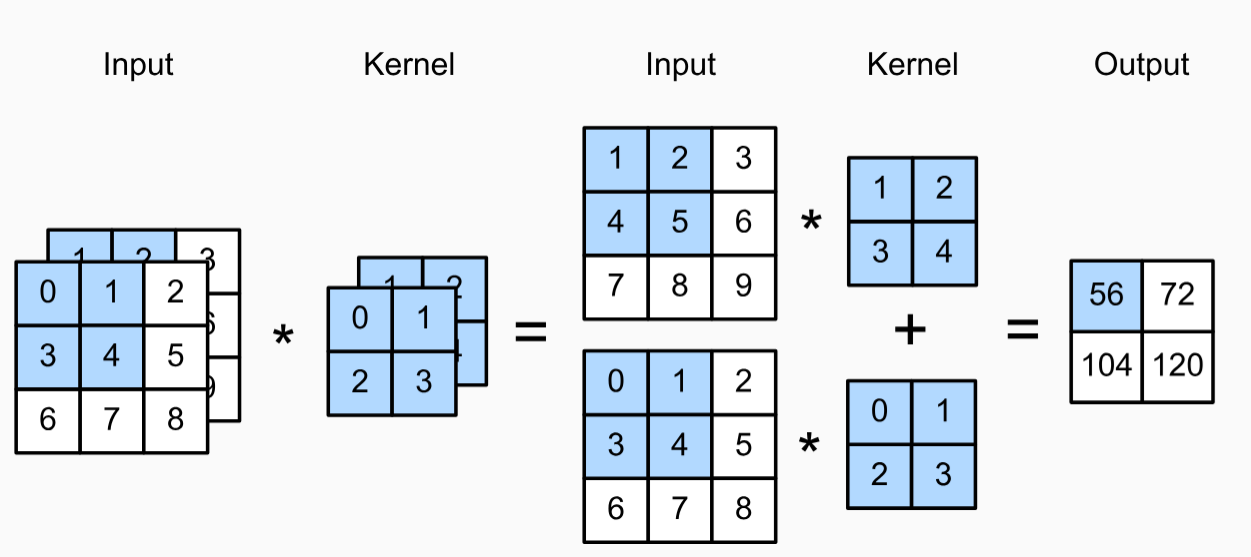

### Numerical Example

In the figure:

- The input has **2 channels**.
- The kernel also has **2 channels**.
- Channel 1 convolution produces one intermediate feature map.
- Channel 2 convolution produces another intermediate feature map.
- The two feature maps are added together to produce **one output feature map**.

For the highlighted output element:

Channel 1 contribution:

```
1×1 + 2×2 + 4×3 + 5×4 = 37
```

Channel 2 contribution:

```
0×0 + 1×1 + 3×2 + 4×3 = 19
```

Final output:

```
37 + 19 = 56
```

The same computation is repeated at every spatial location.

### Implementing Multi-Channel Convolution

The function below performs convolution for multiple input channels.

It applies the 2D cross-correlation to each input channel separately and then sums the results to produce a single output feature map.

In [ ]:
import tensorflow as tf

# ---------------------------------------------------------
# Single-channel 2D cross-correlation
# ---------------------------------------------------------
def corr2d(X, K):
    """
    Apply a 2D kernel to one input channel.

    X shape: (height, width)
    K shape: (kernel_height, kernel_width)
    """

    kernel_height, kernel_width = K.shape

    output_height = X.shape[0] - kernel_height + 1
    output_width = X.shape[1] - kernel_width + 1

    Y = tf.Variable(
        tf.zeros((output_height, output_width), dtype=X.dtype)
    )

    # Slide the kernel over every valid input location
    for i in range(output_height):
        for j in range(output_width):

            # Extract the image region covered by the kernel
            input_patch = X[
                i:i + kernel_height,
                j:j + kernel_width
            ]

            # Multiply corresponding values and sum them
            output_value = tf.reduce_sum(input_patch * K)

            # Store the result in the output feature map
            Y[i, j].assign(output_value)

    return Y


# ---------------------------------------------------------
# Multiple-input-channel cross-correlation
# ---------------------------------------------------------
def corr2d_multi_in(X, K):
    """
    Apply cross-correlation to multiple input channels.

    X shape: (input_channels, height, width)
    K shape: (input_channels, kernel_height, kernel_width)

    Each input channel is processed with its corresponding
    kernel channel. The results are summed to produce one
    output feature map.
    """

    # Apply corr2d() to each input/kernel channel pair
    channel_outputs = [
        corr2d(x, k)
        for x, k in zip(X, K)
    ]

    # Sum the channel results element-wise
    return tf.reduce_sum(channel_outputs, axis=0)

Next, we construct the same multi-channel input and kernel shown in the figure and verify that our implementation produces the expected output.

In [ ]:
# ---------------------------------------------------------
# Create a two-channel input tensor.
#
# Shape:
# (2 input channels, 3 rows, 3 columns)
# ---------------------------------------------------------
X = tf.constant([
    # Input channel 1
    [[0.0, 1.0, 2.0],
     [3.0, 4.0, 5.0],
     [6.0, 7.0, 8.0]],

    # Input channel 2
    [[1.0, 2.0, 3.0],
     [4.0, 5.0, 6.0],
     [7.0, 8.0, 9.0]]
])

# ---------------------------------------------------------
# Create a matching two-channel kernel.
#
# Shape:
# (2 input channels, 2 rows, 2 columns)
#
# The kernel must have the same number of input channels
# as the input tensor.
# ---------------------------------------------------------
K = tf.constant([
    # Kernel for input channel 1
    [[0.0, 1.0],
     [2.0, 3.0]],

    # Kernel for input channel 2
    [[1.0, 2.0],
     [3.0, 4.0]]
])

# Apply multi-channel cross-correlation.
#
# Each input channel is processed separately, and the
# two resulting feature maps are added together.
Y = corr2d_multi_in(X, K)

# Display the result.
print("Output feature map:")
print(Y.numpy())

Output feature map:
[[ 56.  72.]
 [104. 120.]]


The output matches the manual calculation shown earlier.

Although the input contains two channels, the result is **one output feature map** because all channel responses are summed together.

In the next section, we will see how CNNs produce **multiple output channels** by learning multiple filters.

In [ ]:
# Display the shapes to understand
# how channels are stored.

print("Input shape:", X.shape)
print("Kernel shape:", K.shape)
print("Output shape:", Y.shape)

Input shape: (2, 3, 3)
Kernel shape: (2, 2, 2)
Output shape: (2, 2)


Note: In this example, tensors are stored as (channels, height, width) for simplicity. TensorFlow's built-in Conv2D layer typically uses (batch, height, width, channels) instead.

### Multiple Output Channels

In the previous section, we saw that a convolution layer with **one filter** produces **one output feature map**.

In practice, CNNs rarely use just one filter. Instead, they learn **many filters**, each designed to detect a different pattern in the input.

For example, different filters may learn to detect:

- vertical edges
- horizontal edges
- corners
- textures

Since **each filter produces one feature map**, using multiple filters results in multiple output channels.

For example:

- 1 filter → 1 output feature map
- 16 filters → 16 output feature maps
- 64 filters → 64 output feature maps

The following implementation applies multiple filters to the same multi-channel input, producing multiple output feature maps.

In [ ]:
# Apply multiple filters to a multi-channel input.
#
# X shape: (input_channels, height, width)
# K shape: (output_channels, input_channels, kernel_height, kernel_width)

def corr2d_multi_in_out(X, K):

    # Apply each filter independently.
    outputs = [
        corr2d_multi_in(X, k)
        for k in K
    ]

    # Stack the resulting feature maps.
    return tf.stack(outputs, axis=0)

In [ ]:
# Create three different filters.
# Each filter has two input channels and a 2 × 2 kernel.

K = tf.stack((K, K + 1, K + 2), axis=0)

print("Kernel shape:", K.shape)

Kernel shape: (3, 2, 2, 2)


The kernel now has shape **(3, 2, 2, 2)**:

- **3** output filters
- **2** input channels
- **2 × 2** kernel size

Because there are three filters, the convolution layer will produce three output feature maps.

In [ ]:
# Apply the three filters to the input.
Y = corr2d_multi_in_out(X, K)

print("Output shape:", Y.shape)
print(Y.numpy())

Output shape: (3, 2, 2)
[[[ 56.  72.]
  [104. 120.]]

 [[ 76. 100.]
  [148. 172.]]

 [[ 96. 128.]
  [192. 224.]]]


The output has shape **(3, 2, 2)**:

- **3** output channels (one from each filter)
- each feature map has a spatial size of **2 × 2**

This demonstrates an important concept in CNNs:

- **One filter produces one output feature map.**
- **N filters produce N output feature maps (N output channels).**

As CNNs become deeper, the number of filters often increases, allowing the network to learn a richer set of visual features.

In this example, we created **three filters**, each of which operates on the same **two-channel input**. Every filter independently performs a multi-channel convolution and produces **one output feature map**.





So far, we have used convolution kernels such as **3 × 3** and **5 × 5**, which examine a neighborhood of pixels to detect spatial patterns such as edges, corners, and textures.

However, after several convolutional layers, a CNN often produces **many feature maps** (channels). Sometimes we do not want to learn larger spatial patterns—we simply want to **combine or reduce these channels**.

A **1 × 1 convolution** provides an efficient way to do this. Instead of looking at neighboring pixels, it operates on **one pixel location at a time**, combining the values from all input channels to produce new output channels.

As a result:

- the **height and width remain unchanged**, while
- the **number of channels can increase or decrease**.

### 1 × 1 Convolutional Layer

At first glance, a **1 × 1 convolution** may seem unnecessary because the kernel covers only a single pixel.

Unlike larger kernels (e.g., 3 × 3 or 5 × 5), a 1 × 1 convolution **does not combine information from neighboring pixels**. Instead, it operates only across the **channel dimension**.

For each pixel location, the layer takes the values from all input channels, computes a weighted combination of those values, and produces one or more output channels.

As a result:

- The **height and width remain unchanged**.
- Only the **number of channels** changes.

For example, a 1 × 1 convolution can transform an input with **3 channels** into an output with **2 channels** while preserving the spatial dimensions.

The figure below illustrates this process.
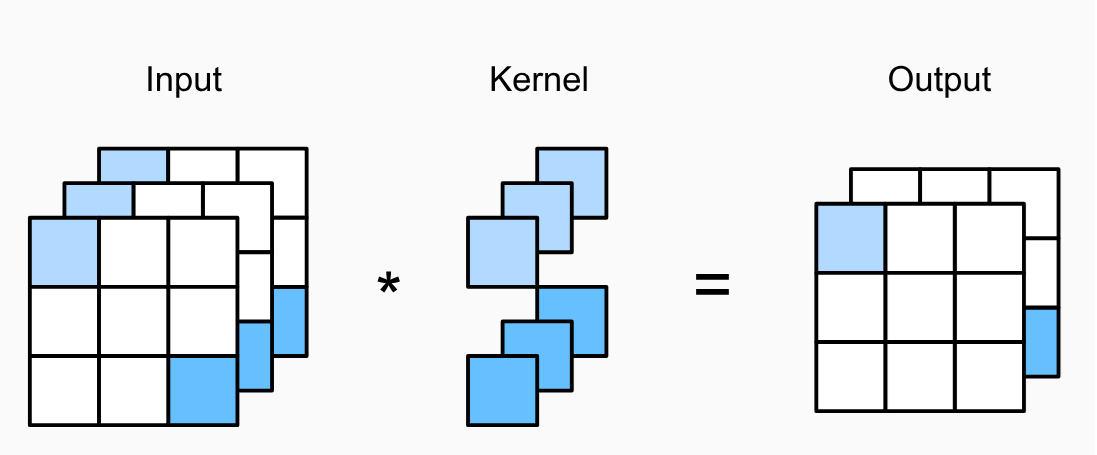

In [ ]:
# Implement a 1 × 1 convolution using matrix multiplication.
#
# X shape: (input_channels, height, width)
# K shape: (output_channels, input_channels, 1, 1)

def corr2d_multi_in_out_1x1(X, K):

    # Extract the input dimensions.
    c_i, h, w = X.shape
    c_o = K.shape[0]

    # Flatten the spatial dimensions.
    X = tf.reshape(X, (c_i, h * w))

    # Remove the singleton kernel dimensions.
    K = tf.reshape(K, (c_o, c_i))

    # Perform matrix multiplication to mix channels.
    Y = tf.matmul(K, X)

    # Restore the spatial dimensions.
    return tf.reshape(Y, (c_o, h, w))

In [ ]:
# Random multi-channel input
X = tf.random.normal((3, 3, 3))

# Two output channels, three input channels, 1 × 1 kernel
K = tf.random.normal((2, 3, 1, 1))

# Compute the outputs using both implementations
Y1 = corr2d_multi_in_out_1x1(X, K)
Y2 = corr2d_multi_in_out(X, K)

# Verify that both implementations produce the same result
# Both functions perform a 1 × 1 convolution using the same input and kernel.
# The first uses matrix multiplication, while the second uses regular convolution.
# We compare their outputs to show that both methods produce the same result.
difference = tf.reduce_sum(tf.abs(Y1 - Y2))

assert float(difference) < 1e-6

# Display the shapes and verification result
print("Input shape:", X.shape)
print("Kernel shape:", K.shape)
print("Output shape:", Y1.shape)
print("Total difference:", float(difference))
print("\nThe two implementations produce the same output.")

Input shape: (3, 3, 3)
Kernel shape: (2, 3, 1, 1)
Output shape: (2, 3, 3)
Total difference: 0.0

The two implementations produce the same output.




The two implementations produce identical results, confirming that a **1 × 1 convolution** is equivalent to applying a fully connected transformation independently at every pixel location.

Unlike larger kernels, a 1 × 1 convolution **does not learn spatial features** because it does not examine neighboring pixels. Instead, it learns how to combine information across the input channels.

For this reason, 1 × 1 convolutions are widely used to:

- reduce the number of channels,
- increase the number of channels, or
- learn better combinations of existing feature maps while preserving the spatial dimensions.

## Summary

So far, we extended convolution from the single-channel case to the multi-channel setting used in modern convolutional neural networks (CNNs).

The main ideas are:

- **Multiple input channels:** A convolution kernel must have the same number of input channels as the input feature map. Each channel is convolved separately using its corresponding kernel, and the resulting feature maps are summed to produce one output feature map.

- **Multiple output channels:** A convolutional layer typically learns multiple filters. Each filter produces one output feature map, so the number of filters determines the number of output channels.

- **1 × 1 convolution:** A 1 × 1 convolution operates only across the channel dimension while preserving the height and width of the feature map. It is commonly used to increase or reduce the number of channels with relatively few parameters.

These concepts allow CNNs to learn many different features simultaneously while efficiently transforming and combining information across channels.

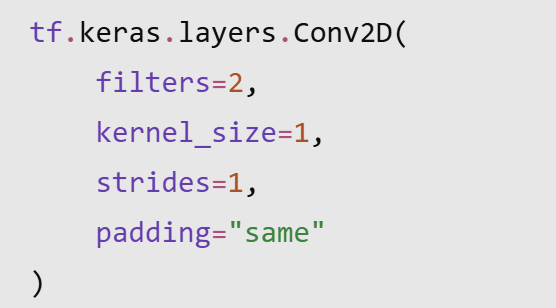

# Pooling

Convolutional layers learn useful local features, but the resulting feature maps can still be very large.

Pooling layers reduce the spatial dimensions (height and width) of feature maps while preserving the most important information. This makes the network more computationally efficient and helps it become less sensitive to small shifts in the input image.

Unlike convolution, pooling does **not** use learnable filters. Instead, it summarizes values within a small window.

The two most common pooling operations are:

- **Max pooling**, which selects the largest value in each pooling window.
- **Average pooling**, which computes the average value in each pooling window.